# 01: Data Types, Dispersion Analysis & Distribution Fitting
**Syllabus Coverage:** Unit I (Stats & Distribution Fitting) & Unit II (Data Types & Stats)

### Objectives:
1. Establish an explicit attribute taxonomy (Continuous, Discrete, Nominal, Ordinal, Binary).
2. Compute comprehensive dispersion metrics: Five-number summary, Mean, Median, Mode, Variance, Std Dev, IQR, Skewness, and Kurtosis.
3. Conduct Weekday vs. Weekend dispersion analysis.
4. Fit parametric probability distributions (Normal, Gamma, Weibull) to Carbon Intensity and evaluate goodness-of-fit via Kolmogorov-Smirnov test.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Ensure src package is importable
sys.path.insert(0, os.path.abspath('..'))
from src.preprocessing import load_clean_data
from src.statistics import (
    get_feature_taxonomy,
    compute_dispersion_summary,
    weekday_vs_weekend_comparison,
    fit_probability_distributions,
)

sns.set_theme(style='darkgrid')
print('Libraries successfully imported.')

Libraries successfully imported.


## 1. Explicit Attribute Taxonomy (Unit II)
A structured breakdown of all telemetry signals by measurement scale and mathematical type.

In [2]:
taxonomy_df = get_feature_taxonomy()
taxonomy_df

,Attribute,Taxonomy Type,Measurement Unit,Description
0,timestamp,Nominal / Temporal,ISO 8601 YYYY-MM-DD HH:MM:SS,Hourly synchronized telemetry timestamp
1,hour,Discrete / Cyclical,Hours [0 - 23],Hour of the day in 24h format
2,day_of_week,Ordinal,Index [0 - 6],"Day index (0 = Monday, 6 = Sunday)"
3,day_name,Nominal,String label,Calendar day of the week
4,is_weekend,Binary,"Boolean flag {0, 1}","1 if Saturday/Sunday, else 0"
5,season,Nominal,Categorical string,"Climatic season (Winter, Spring, Summer, Fall)"
6,temperature_c,Continuous,Degrees Celsius (°C),Ambient outside surface temperature
7,grid_load_mw,Continuous,Megawatts (MW),Total active demand draw across electrical bal...
8,gen_coal_mw,Continuous,Megawatts (MW),Thermal coal baseload dispatch power
9,gen_gas_mw,Continuous,Megawatts (MW),Natural gas peaker / load-following dispatch


## 2. Five-Number Summary & Dispersion Analysis (Unit II)
Computing Min, Q1 (25th), Median (50th), Q3 (75th), Max, alongside Mean, Mode, Variance, Std Dev, IQR, Skewness, and Kurtosis.

In [3]:
df = load_clean_data('../data/processed/grid_telemetry_clean.csv')
dispersion_df = compute_dispersion_summary(df)
dispersion_df

,Feature,Count,Mean,Median,Mode,Variance,Std Dev,Min,Q1 (25%),Q3 (75%),Max,IQR,Skewness,Kurtosis
0,grid_load_mw,8760,29104.75,29187.50,44516.50,22042345.08,4694.93,18179.00,25121.50,32879.50,44516.50,7758.00,0.106,-0.774
1,temperature_c,8760,16.03,15.18,38.49,54.85,7.41,-1.14,10.17,21.49,38.49,11.33,0.290,-0.639
2,carbon_intensity_gco2_per_kwh,8760,237.00,247.41,190.44,4850.67,69.65,76.60,179.12,293.26,408.26,114.14,-0.263,-0.920
3,gen_coal_mw,8760,4045.46,4219.00,6173.00,3335042.14,1826.21,700.00,2421.75,5658.25,7725.00,3236.50,-0.119,-1.194
4,gen_gas_mw,8760,5817.54,5294.00,4180.00,3852970.90,1962.90,0.00,4334.00,6815.25,13292.00,2481.25,1.041,0.608
5,gen_solar_mw,8760,1372.60,560.00,15.00,2749415.38,1658.14,2.00,52.00,2438.25,5792.00,2386.25,1.079,-0.196
6,gen_wind_mw,8760,5585.26,4963.00,6750.00,10944335.49,3308.22,243.00,2913.00,7707.00,16063.00,4794.00,0.670,-0.257
7,gen_nuclear_mw,8760,6082.08,6071.00,6078.00,720083.88,848.58,998.00,5062.00,6978.00,7117.00,1916.00,-0.336,-0.921
8,gen_hydro_mw,8760,4124.46,3832.00,2533.00,3855416.21,1963.52,795.00,2537.00,5390.00,11613.00,2853.00,0.678,0.003
9,tariff_inr_per_kwh,8760,9.67,9.50,9.50,8.37,2.89,6.50,6.50,11.00,14.50,4.50,0.542,-0.895


## 3. Weekday vs. Weekend Dispersion Comparison (Unit II)
Comparing grid demand characteristics between commercial workdays and weekends.

Weekday Mean Load: 29,829.1 MW (Std: 4,691.3 MW, IQR: 7,969.2 MW)
Weekend Mean Load: 27,286.8 MW (Std: 4,185.0 MW, IQR: 5,621.8 MW)
Average Weekend Load Drop: 8.52%


C:\Users\krish\AppData\Local\Temp\ipykernel_5904\4251124677.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_weekend', y='grid_load_mw', palette=['#38BDF8', '#F43F5E'], ax=ax)
C:\Users\krish\AppData\Local\Temp\ipykernel_5904\4251124677.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Weekday (Mon-Fri)', 'Weekend (Sat-Sun)'])


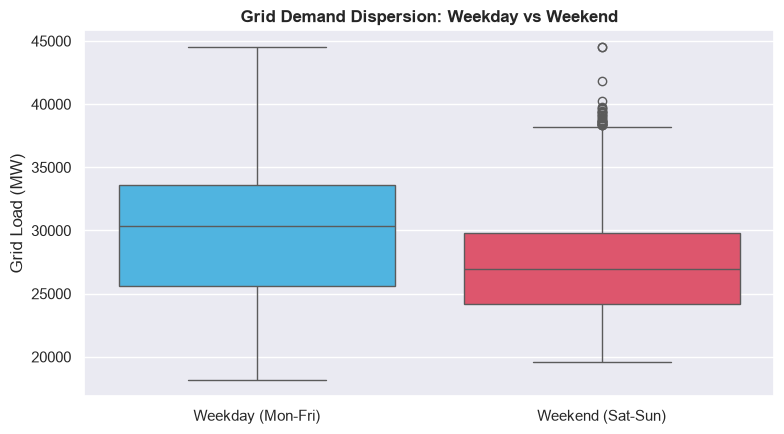

In [4]:
comp = weekday_vs_weekend_comparison(df, metric='grid_load_mw')
print(f"Weekday Mean Load: {comp['weekday']['mean']:,.1f} MW (Std: {comp['weekday']['std']:,.1f} MW, IQR: {comp['weekday']['iqr']:,.1f} MW)")
print(f"Weekend Mean Load: {comp['weekend']['mean']:,.1f} MW (Std: {comp['weekend']['std']:,.1f} MW, IQR: {comp['weekend']['iqr']:,.1f} MW)")
print(f"Average Weekend Load Drop: {comp['load_drop_pct']}%")

# Visualization
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x='is_weekend', y='grid_load_mw', palette=['#38BDF8', '#F43F5E'], ax=ax)
ax.set_xticklabels(['Weekday (Mon-Fri)', 'Weekend (Sat-Sun)'])
ax.set_title('Grid Demand Dispersion: Weekday vs Weekend', fontsize=12, fontweight='bold')
ax.set_ylabel('Grid Load (MW)')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

## 4. Probability Distribution Fitting (Unit I)
Fitting continuous theoretical distributions to empirical Carbon Intensity ($CI_t$) and assessing goodness of fit using the Kolmogorov-Smirnov test.

Normal   -> KS Stat: 0.0713, p-val: 3.6531e-39, Params: {'mean': 237.0, 'std': 69.64}
Gamma    -> KS Stat: 0.0782, p-val: 4.9796e-47, Params: {'shape_a': 328.06, 'loc': -1032.28, 'scale': 3.87}
Weibull  -> KS Stat: 0.0556, p-val: 5.3931e-24, Params: {'shape_c': 4.92, 'loc': -53.95, 'scale': 318.0}


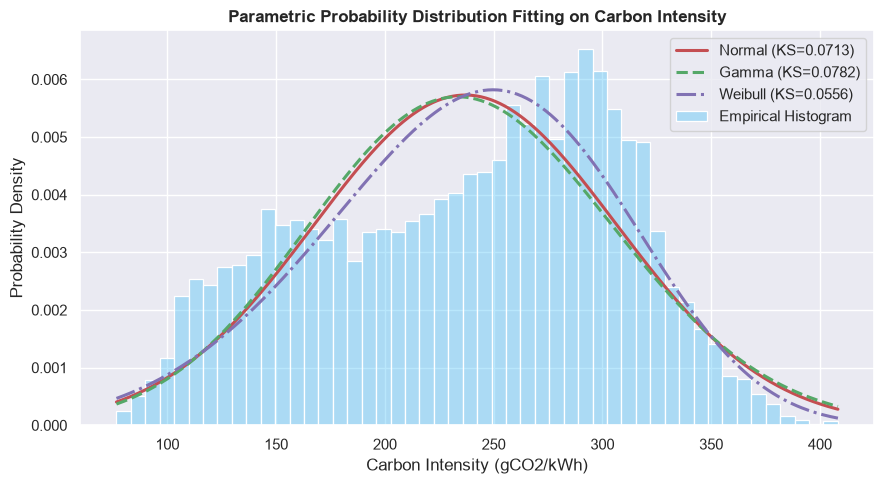

In [5]:
fits = fit_probability_distributions(df, column='carbon_intensity_gco2_per_kwh')
for dist_name, res in fits.items():
    print(f"{dist_name:8s} -> KS Stat: {res['ks_stat']:.4f}, p-val: {res['ks_pvalue']:.4e}, Params: {res['params']}")

# Plot distributions overlaid on histogram
ci_vals = df['carbon_intensity_gco2_per_kwh'].dropna().values
x_eval = np.linspace(ci_vals.min(), ci_vals.max(), 300)

plt.figure(figsize=(9, 5))
sns.histplot(ci_vals, stat='density', bins=50, color='#38BDF8', alpha=0.35, label='Empirical Histogram')

# Normal fit
mu, std = fits['Normal']['params']['mean'], fits['Normal']['params']['std']
plt.plot(x_eval, stats.norm.pdf(x_eval, mu, std), 'r-', lw=2.2, label=f"Normal (KS={fits['Normal']['ks_stat']})")

# Gamma fit
gp = fits['Gamma']['params']
plt.plot(x_eval, stats.gamma.pdf(x_eval, gp['shape_a'], gp['loc'], gp['scale']), 'g--', lw=2.2, label=f"Gamma (KS={fits['Gamma']['ks_stat']})")

# Weibull fit
wp = fits['Weibull']['params']
plt.plot(x_eval, stats.weibull_min.pdf(x_eval, wp['shape_c'], wp['loc'], wp['scale']), 'm-.', lw=2.2, label=f"Weibull (KS={fits['Weibull']['ks_stat']})")

plt.title('Parametric Probability Distribution Fitting on Carbon Intensity', fontsize=12, fontweight='bold')
plt.xlabel('Carbon Intensity (gCO2/kWh)')
plt.ylabel('Probability Density')
plt.legend()
plt.tight_layout()
plt.show()